# 04 · ¿Qué tiendas venden menos de lo que deberían?

**Pregunta de negocio.** Comparadas contra tiendas equivalentes, ¿qué tiendas están por debajo,
cuánto dinero hay en juego y dónde están?

**Cómo leer este notebook.** La lógica vive en `src/retail_analytics/potential.py`. Cada sección
cierra con una **conclusión**.

| # | Sección |
|---|---|
| 1 | Método: venta esperada e índice de desempeño |
| 2 | ¿El desempeño de cada tienda es estable? |
| 3 | Oportunidad en dos escenarios (P50 y P75) |
| 4 | ¿Qué tan sensible es la cifra al método? |
| 5 | ¿Dónde está la oportunidad? Vista regional |
| 6 | Matriz de tiendas: desempeño comercial × carga de cajas |
| 7 | Tiendas a priorizar |
| 8 | Conclusiones y limitaciones |

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

from retail_analytics import potential as pt
from retail_analytics import viz
from retail_analytics.cleaning import build_clean_panel
from retail_analytics.config import PROJECT_ROOT, project_path
from retail_analytics.io import load_raw

viz.set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

raw = load_raw()
panel = build_clean_panel(raw.transactions, raw.stores, raw.calendar)
tiendas = pt.opportunity(pt.performance_index(pt.store_table(panel)))
tiendas["cuadrante"] = pt.quadrant(tiendas)
print(f"Tiendas: {len(tiendas)} · venta anual total: {tiendas['annual_sales'].sum() / 1e6:,.0f} M MXN · R² del modelo: {tiendas.attrs['r2']:.2f}")

Tiendas: 80 · venta anual total: 29,884 M MXN · R² del modelo: 0.89


## 1 · Método: venta esperada e índice de desempeño

Comparar una Express de nivel C en el Sur contra un Supercenter A/B del Norte no tiene sentido.
Para comparar a cada tienda con sus equivalentes:

1. Se estima la **venta esperada** de cada tienda con una regresión del logaritmo de su venta
   diaria contra lo que la tienda **no controla** en el corto plazo: formato, región, nivel
   socioeconómico de la zona y tamaño.
2. El **índice de desempeño** es `venta real / venta esperada`. Un índice de 0.85 significa que la
   tienda vende 15% menos que una tienda con sus mismas características.
3. La **meta** de cada tienda es el índice mediano (P50, escenario conservador) o el percentil 75
   (P75, escenario ambicioso) **de su formato**. Una tienda que ya está arriba de la meta no
   suma oportunidad: la meta nunca baja la venta de nadie.

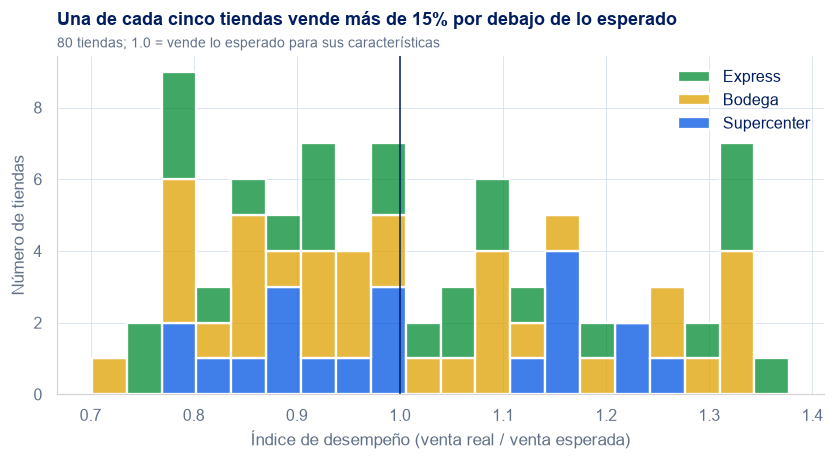

Tiendas >15% abajo: 17 · >15% arriba: 21


In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=tiendas, x="index", hue="store_format", hue_order=viz.FORMAT_ORDER, palette=viz.FORMAT_COLORS,
             bins=20, multiple="stack", edgecolor=viz.SURFACE, linewidth=1.5, ax=ax)
ax.axvline(1, color=viz.INK, linewidth=1)
ax.set(xlabel="Índice de desempeño (venta real / venta esperada)", ylabel="Número de tiendas")
ax.set_title("Una de cada cinco tiendas vende más de 15% por debajo de lo esperado")
viz.subtitle(ax, "80 tiendas; 1.0 = vende lo esperado para sus características")
sns.move_legend(ax, "upper right", title="")
plt.show()
print(f"Tiendas >15% abajo: {(tiendas['index'] < 0.85).sum()} · >15% arriba: {(tiendas['index'] > 1.15).sum()}")

## 2 · ¿El desempeño de cada tienda es estable?

Si el índice fuera suerte de unos meses, no tendría sentido ponerle metas. Se calcula el índice
por separado con enero-julio y con agosto-febrero.

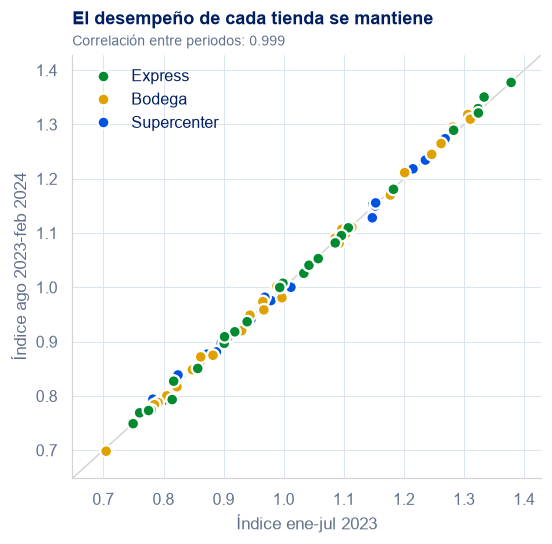

In [3]:
corte = pd.Timestamp("2023-08-01")
idx1 = pt.performance_index(pt.store_table(panel[panel["date"] < corte])).set_index("store_id")["index"]
idx2 = pt.performance_index(pt.store_table(panel[panel["date"] >= corte])).set_index("store_id")["index"]
estab = pd.DataFrame({"ene-jul": idx1, "ago-feb": idx2}).join(tiendas.set_index("store_id")["store_format"])
fig, ax = plt.subplots(figsize=(5.5, 5))
sns.scatterplot(data=estab, x="ene-jul", y="ago-feb", hue="store_format", hue_order=viz.FORMAT_ORDER,
                palette=viz.FORMAT_COLORS, s=60, edgecolor=viz.SURFACE, linewidth=1.5, ax=ax)
lim = (estab[["ene-jul", "ago-feb"]].min().min() - 0.05, estab[["ene-jul", "ago-feb"]].max().max() + 0.05)
ax.plot(lim, lim, color=viz.AXIS, linewidth=1, zorder=0)
ax.set(xlim=lim, ylim=lim, xlabel="Índice ene-jul 2023", ylabel="Índice ago 2023-feb 2024")
ax.set_title("El desempeño de cada tienda se mantiene")
viz.subtitle(ax, f"Correlación entre periodos: {estab['ene-jul'].corr(estab['ago-feb']):.3f}")
ax.legend(title="")
plt.show()

> **Conclusión.** El índice es prácticamente idéntico en ambos periodos. Las brechas no son
> ruido: son características persistentes de cada tienda, y por eso es razonable fijarles metas.

## 3 · Oportunidad en dos escenarios

In [4]:
venta = tiendas["annual_sales"].sum()
esc = pd.DataFrame(
    {
        "meta": ["Mediana de su formato (P50)", "Percentil 75 de su formato (P75)"],
        "tiendas con brecha": [(tiendas["gap_p50"] > 0).sum(), (tiendas["gap_p75"] > 0).sum()],
        "oportunidad anual (M MXN)": [tiendas["gap_p50"].sum() / 1e6, tiendas["gap_p75"].sum() / 1e6],
        "% de la venta actual": [tiendas["gap_p50"].sum() / venta, tiendas["gap_p75"].sum() / venta],
    },
    index=["Conservador", "Ambicioso"],
)
esc.style.format({"oportunidad anual (M MXN)": "{:,.0f}", "% de la venta actual": "{:.1%}"})

,meta,tiendas con brecha,oportunidad anual (M MXN),% de la venta actual
Conservador,Mediana de su formato (P50),39,"1,707",5.7%
Ambicioso,Percentil 75 de su formato (P75),59,"4,420",14.8%


> **Conclusión.** Si las tiendas por debajo de la mediana de su formato alcanzaran a la tienda
> típica, la cadena vendería **~1,700 M MXN más al año (+5.7%)**. Con la meta ambiciosa (P75),
> ~4,400 M MXN (+14.8%). El escenario P50 es la meta realista para un primer año.

## 4 · ¿Qué tan sensible es la cifra al método?

La cifra depende de qué se considere "fuera del control de la tienda". Se recalcula con tres
definiciones de tienda comparable.

In [5]:
alternativas = {
    "Solo formato y tamaño": "np.log(daily_sales) ~ C(store_format) + np.log(size_sqm)",
    "Formato, tamaño y nivel socioeconómico": "np.log(daily_sales) ~ C(store_format) + C(socioeconomic_level) + np.log(size_sqm)",
    "Formato, tamaño, nivel socioeconómico y región (elegido)": pt.FORMULA,
}
filas = []
for nombre, f in alternativas.items():
    t = pt.opportunity(pt.performance_index(pt.store_table(panel), f))
    filas.append({"definición de comparable": nombre, "R²": t.attrs["r2"], "P50 (M MXN)": t["gap_p50"].sum() / 1e6, "P75 (M MXN)": t["gap_p75"].sum() / 1e6})
pd.DataFrame(filas).set_index("definición de comparable").style.format({"R²": "{:.2f}", "P50 (M MXN)": "{:,.0f}", "P75 (M MXN)": "{:,.0f}"})

,R²,P50 (M MXN),P75 (M MXN)
definición de comparable,,,
Solo formato y tamaño,0.79,"2,317","6,465"
"Formato, tamaño y nivel socioeconómico",0.86,"2,063","4,640"
"Formato, tamaño, nivel socioeconómico y región (elegido)",0.89,"1,707","4,420"


> **Conclusión.** Con definiciones menos estrictas la oportunidad crece, pero eso le atribuye a la
> tienda diferencias de mercado que no puede cambiar (poder adquisitivo de la zona, región). Se
> elige la definición más completa: es la **cifra conservadora y defendible**.

## 5 · ¿Dónde está la oportunidad? Vista regional

Las tiendas no tienen coordenadas, así que el mapa es **por región**, con una asignación de
estados a regiones que es un **supuesto** (los datos no la incluyen; está en
`potential.REGION_STATES`). Cada cifra se calcula por tienda y luego se suma por región.

In [6]:
reg = tiendas.groupby("region", observed=True).agg(
    tiendas=("store_id", "size"),
    venta_anual=("annual_sales", "sum"),
    oportunidad_p50=("gap_p50", "sum"),
    oportunidad_p75=("gap_p75", "sum"),
    indice_mediano=("index", "median"),
    tiendas_bajo_85=("index", lambda s: (s < 0.85).sum()),
)
reg["oportunidad P50 (% venta)"] = reg["oportunidad_p50"] / reg["venta_anual"]
reg_m = reg.copy()
for c in ["venta_anual", "oportunidad_p50", "oportunidad_p75"]:
    reg_m[c] = reg_m[c] / 1e6
reg_m.sort_values("oportunidad_p50", ascending=False).style.format(
    {"venta_anual": "{:,.0f}", "oportunidad_p50": "{:,.0f}", "oportunidad_p75": "{:,.0f}",
     "indice_mediano": "{:.2f}", "oportunidad P50 (% venta)": "{:.1%}"}
)

,tiendas,venta_anual,oportunidad_p50,oportunidad_p75,indice_mediano,tiendas_bajo_85,oportunidad P50 (% venta)
region,,,,,,,
Norte,17,"6,453",449,"1,002",1.03,5,7.0%
Occidente,20,"7,662",387,"1,083",0.98,4,5.1%
Centro,12,"4,528",383,755,0.88,4,8.5%
Oriente,18,"6,080",326,941,0.99,3,5.4%
Sur,13,"5,162",161,640,0.99,1,3.1%


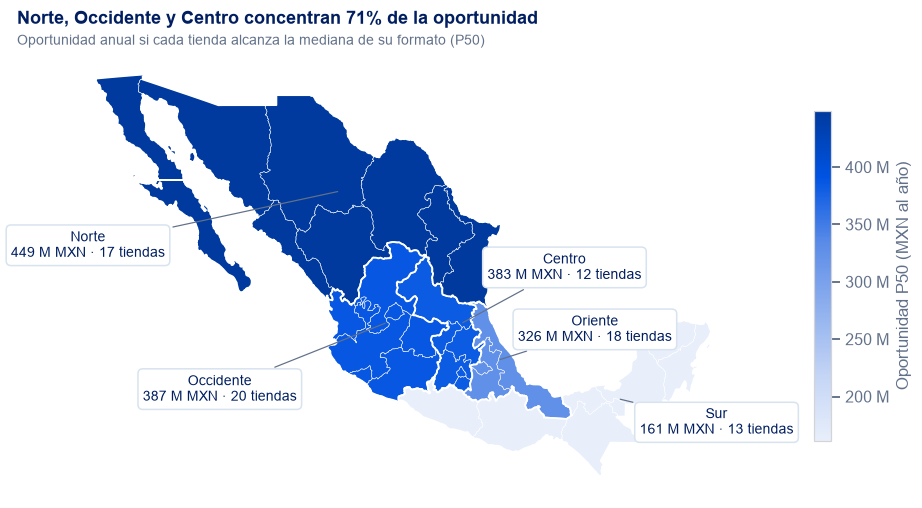

In [7]:
estados = gpd.read_file(PROJECT_ROOT / "data/external/mexico_estados.geojson")
estados = estados.merge(pt.state_regions(), left_on="name", right_on="estado", how="left")
regiones = estados.dissolve(by="region").join(reg)
cmap = LinearSegmentedColormap.from_list("azul", viz.SEQ_BLUE[:6])

fig, ax = plt.subplots(figsize=(11, 6.5))
regiones.plot(column="oportunidad_p50", cmap=cmap, edgecolor=viz.SURFACE, linewidth=1.2, ax=ax, legend=True,
              legend_kwds={"label": "Oportunidad P50 (MXN al año)", "shrink": 0.6, "format": lambda v, _: f"{v / 1e6:,.0f} M"})
estados.boundary.plot(ax=ax, color=viz.SURFACE, linewidth=0.3)
# Etiquetas fuera de los polígonos (en el mar) con una línea guía hacia su región.
posiciones = {"Norte": (-117.5, 25.0), "Occidente": (-111.0, 18.5), "Centro": (-94.0, 24.0), "Oriente": (-92.5, 21.2), "Sur": (-86.5, 17.0)}
for region, row in regiones.iterrows():
    p = row.geometry.representative_point()
    ax.annotate(
        f"{region}\n{row['oportunidad_p50'] / 1e6:,.0f} M MXN · {row['tiendas']} tiendas",
        xy=(p.x, p.y), xytext=posiciones[region], ha="center", va="center", fontsize=9, color=viz.INK,
        bbox={"boxstyle": "round,pad=0.35", "fc": viz.SURFACE, "ec": viz.GRID},
        arrowprops={"arrowstyle": "-", "color": viz.INK_2, "linewidth": 0.8},
    )
ax.set_xlim(-121, -84)
ax.set_axis_off()
ax.set_title("Norte, Occidente y Centro concentran 71% de la oportunidad")
viz.subtitle(ax, "Oportunidad anual si cada tienda alcanza la mediana de su formato (P50)")
plt.show()

In [8]:
# Mapa interactivo (estilo de los mapas RTM): se guarda como HTML en reports/.
import folium

m = folium.Map(location=[23.6, -102.5], zoom_start=5, tiles="OpenStreetMap")
reg_geo = regiones.reset_index()[["region", "geometry", "tiendas", "oportunidad_p50", "oportunidad_p75", "indice_mediano", "tiendas_bajo_85"]].copy()
reg_geo["oportunidad_p50_m"] = (reg_geo["oportunidad_p50"] / 1e6).round(0)
reg_geo["oportunidad_p75_m"] = (reg_geo["oportunidad_p75"] / 1e6).round(0)
folium.Choropleth(
    geo_data=reg_geo.to_json(), data=reg_geo, columns=["region", "oportunidad_p50_m"], key_on="feature.properties.region",
    fill_color="Blues", fill_opacity=0.8, line_color="#FFFFFF", legend_name="Oportunidad P50 (M MXN al año)",
).add_to(m)
folium.GeoJson(
    reg_geo.to_json(),
    style_function=lambda f: {"fillOpacity": 0, "color": "#001E60", "weight": 1},
    tooltip=folium.GeoJsonTooltip(
        fields=["region", "tiendas", "tiendas_bajo_85", "oportunidad_p50_m", "oportunidad_p75_m", "indice_mediano"],
        aliases=["Región", "Tiendas", "Tiendas >15% abajo", "Oportunidad P50 (M MXN)", "Oportunidad P75 (M MXN)", "Índice mediano"],
    ),
).add_to(m)
salida = project_path("figures") / "mapa_potencial_regional.html"
m.save(salida)
print(f"Mapa interactivo guardado en {salida.relative_to(PROJECT_ROOT)}")

Mapa interactivo guardado en reports/figures/mapa_potencial_regional.html


> **Conclusión.** Norte (449 M), Occidente (387 M) y Centro (383 M) concentran el 71% de la
> oportunidad P50; el Sur aporta menos (161 M). En proporción a su venta, **Centro (8.5%) y
> Norte (7.0%)** son las regiones con más espacio de mejora.

## 6 · Matriz de tiendas: desempeño comercial × carga de cajas

Saber que una tienda vende poco no dice qué hacer. Cruzar el desempeño con la carga de sus cajas
(transacciones diarias por caja, frente a la mediana de su formato) separa causas distintas:

| Cuadrante | Desempeño | Cajas | Lectura | Acción |
|---|---|---|---|---|
| **Crecer** | Bajo | Holgadas | Hay capacidad, falta tráfico o conversión | Comercial: surtido, precio, exhibición, mercadeo local |
| **Revisar operación** | Bajo | Saturadas | La operación podría estar frenando la venta | Operativa: cajas abiertas, personal en horas pico |
| **Ampliar capacidad** | Alto | Saturadas | Vende bien y está al límite | Inversión: más cajas o autoservicio |
| **Mantener y replicar** | Alto | Holgadas | Funciona | Documentar prácticas y replicarlas |

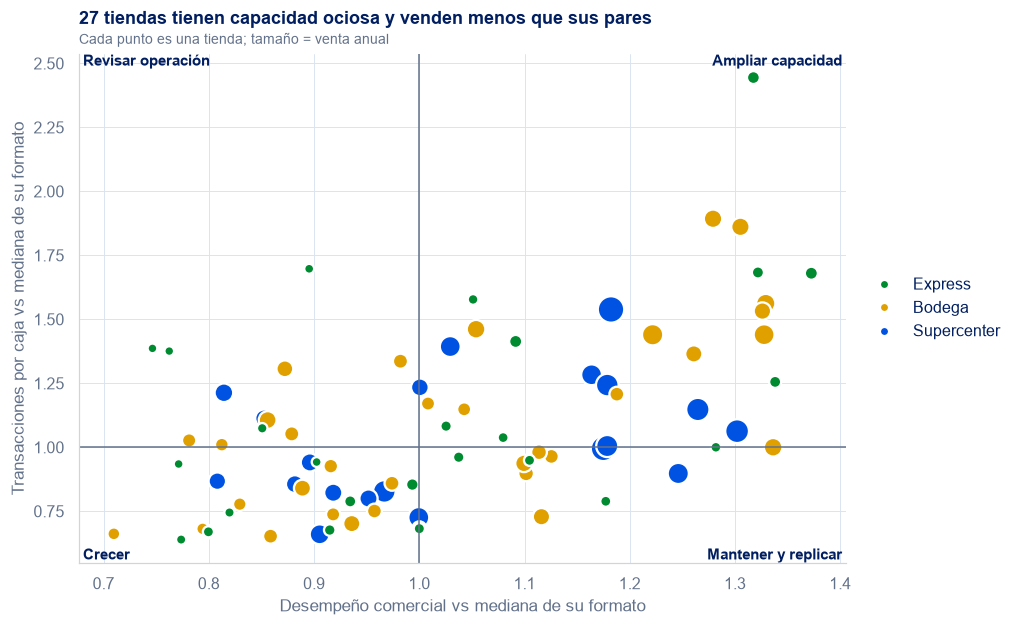

In [9]:
g = tiendas.groupby("store_format", observed=True)
tiendas["desempeño vs formato"] = tiendas["index"] / g["index"].transform("median")
tiendas["carga vs formato"] = tiendas["tx_per_checkout"] / g["tx_per_checkout"].transform("median")

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=tiendas, x="desempeño vs formato", y="carga vs formato", hue="store_format", hue_order=viz.FORMAT_ORDER,
                palette=viz.FORMAT_COLORS, size="annual_sales", sizes=(40, 300), edgecolor=viz.SURFACE, linewidth=1.5, ax=ax)
ax.axvline(1, color=viz.INK_2, linewidth=1)
ax.axhline(1, color=viz.INK_2, linewidth=1)
x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
for x, y, txt, ha, va in [(x0, y0, "Crecer", "left", "bottom"), (x0, y1, "Revisar operación", "left", "top"),
                          (x1, y1, "Ampliar capacidad", "right", "top"), (x1, y0, "Mantener y replicar", "right", "bottom")]:
    ax.text(x, y, f" {txt} ", ha=ha, va=va, fontsize=10, fontweight="bold", color=viz.INK)
ax.set(xlabel="Desempeño comercial vs mediana de su formato", ylabel="Transacciones por caja vs mediana de su formato")
ax.set_title("27 tiendas tienen capacidad ociosa y venden menos que sus pares")
viz.subtitle(ax, "Cada punto es una tienda; tamaño = venta anual")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[1:4], labels[1:4], title="", loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.show()

In [10]:
cuad = tiendas.groupby("cuadrante").agg(
    tiendas=("store_id", "size"), oportunidad_p50=("gap_p50", "sum"), oportunidad_p75=("gap_p75", "sum"), venta=("annual_sales", "sum")
)
cuad[["oportunidad_p50", "oportunidad_p75", "venta"]] /= 1e6
cuad.loc[["Crecer", "Revisar operación", "Ampliar capacidad", "Mantener y replicar"]].style.format(
    {"oportunidad_p50": "{:,.0f}", "oportunidad_p75": "{:,.0f}", "venta": "{:,.0f}"}
)

,tiendas,oportunidad_p50,oportunidad_p75,venta
cuadrante,,,,
Crecer,27,"1,059","2,643","8,934"
Revisar operación,12,649,"1,296","3,560"
Ampliar capacidad,29,0,327,"12,996"
Mantener y replicar,12,0,153,"4,395"


> **Conclusión.** Las 27 tiendas de **Crecer** concentran ~1,060 M MXN de la oportunidad P50: es
> donde una acción comercial tiene más retorno, porque la capacidad ya existe. Las 12 de
> **Revisar operación** suman ~650 M MXN y requieren primero un diagnóstico operativo en campo.

## 7 · Tiendas a priorizar

In [11]:
top = tiendas.sort_values("gap_p50", ascending=False).head(15)[
    ["store_id", "store_format", "region", "socioeconomic_level", "cuadrante", "index", "annual_sales", "gap_p50", "gap_p75"]
].copy()
top[["annual_sales", "gap_p50", "gap_p75"]] /= 1e6
top.rename(columns={"index": "índice", "annual_sales": "venta anual (M)", "gap_p50": "oport. P50 (M)", "gap_p75": "oport. P75 (M)"}).style.format(
    {"índice": "{:.2f}", "venta anual (M)": "{:,.0f}", "oport. P50 (M)": "{:,.0f}", "oport. P75 (M)": "{:,.0f}"}
).hide(axis="index")

store_id,store_format,region,socioeconomic_level,cuadrante,índice,venta anual (M),oport. P50 (M),oport. P75 (M)
STR_012,Supercenter,Norte,C+,Revisar operación,0.80,495,113,221
STR_019,Supercenter,Norte,C,Crecer,0.79,436,104,200
STR_038,Bodega,Norte,C,Crecer,0.70,232,95,146
STR_027,Bodega,Centro,C+,Revisar operación,0.77,291,81,140
STR_009,Supercenter,Centro,C,Revisar operación,0.83,443,77,170
STR_040,Bodega,Norte,A/B,Revisar operación,0.85,452,76,159
STR_036,Bodega,Occidente,C,Crecer,0.79,262,66,117
STR_029,Bodega,Centro,C,Revisar operación,0.80,266,61,113
STR_006,Supercenter,Oriente,C+,Crecer,0.86,454,61,153
STR_020,Supercenter,Sur,B,Crecer,0.88,565,59,171


In [12]:
cobertura = tiendas.sort_values("gap_p50", ascending=False)["gap_p50"].cumsum() / tiendas["gap_p50"].sum()
print(f"Las 15 tiendas con mayor brecha concentran {cobertura.iloc[14]:.0%} de la oportunidad P50")
tiendas.to_csv(project_path("processed") / "potencial_tiendas.csv", index=False)

Las 15 tiendas con mayor brecha concentran 63% de la oportunidad P50


## 8 · Conclusiones y limitaciones

**Conclusiones**

1. Formato, región, nivel socioeconómico y tamaño explican ~89% de la diferencia de venta entre
   tiendas. El resto es **desempeño propio de cada tienda, estable en el tiempo**.
2. Llevar a cada tienda a la mediana de su formato vale **~1,700 M MXN al año (+5.7%)**; al P75,
   ~4,400 M MXN (+14.8%).
3. La oportunidad se concentra en pocas tiendas: las 15 con mayor brecha son el primer frente.
4. La matriz separa dónde la palanca es **comercial** (27 tiendas, ~1,060 M MXN) y dónde es
   **operativa** (12 tiendas, ~650 M MXN).

**Limitaciones**

- La brecha mide **cuánto**, no **por qué**: puede haber competencia local, accesos o
  ubicación que el modelo no ve. La recomendación es usarla para **priorizar visitas de
  diagnóstico**, no como meta automática.
- Con 80 tiendas, el modelo de venta esperada tiene pocos grados de libertad; por eso se usa
  una especificación simple y se reporta la sensibilidad (sección 4).
- La asignación de estados a regiones es un supuesto para el mapa; no afecta ninguna cifra.
- La carga de cajas se mide en transacciones diarias, sin el detalle por hora que mostraría la
  saturación real en horas pico.